In [1]:
import numpy as np
import matplotlib.pyplot as plt
import toolbox as funcs
import sim_funcs as sim
import os
import pickle
import scipy.io
import time

In [2]:
network_params = {"realizations": 200  #(200 originally) small scale realizations  (Critical : should be a large value if large number APs and UEs are used)
                    , "tau_c": 200 # total samples in coherence block
                    , "tau_p": 2  # samples for pilots
                    , "p_k": 200  # uplink max power (mW)
                                     }

area_params = {"delta_h": 10 # height difference
                    , "area": 100  # lxl Service Area
                    , "bandwidth": 100e6
                    , "L": 20  # APs
                    , "N": 20  # antennas per AP
                    , "K": 2  # UEs
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 8  # Shadow fading LoS (dB)
                    , "AP_pos_rand": True
                                     }

sim_params = {"setups": 5000,
                     "batch":network_params["realizations"],
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "tests" :50
                    }

In [14]:
area_block_1 = pickle.load(open("Areas Sim/results_L20N20K3_rician0.pkl", "rb"))
area_block_2 = pickle.load(open("Areas Sim/results_L20N20K3_rician100.pkl", "rb"))

# print(area_block_1[2] == area_block_2[2])

[[[[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  ...

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]]


 [[[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True 

In [9]:
area_block = sim.create_areas(area_params, sim_params["tests"])

In [166]:
# test_tau = [1,2,3,4,6,8,10,15,20]
test_tau = [3]
results = {}
for tau in test_tau:
    results[tau] = sim.run_test(network_params, area_params, sim_params, area_block, tau)

data = {
    "area_params" : area_params,
    "test_tau" : test_tau,
    "results" : results
}

L = area_params["L"]
N = area_params["N"]
K = area_params["K"]


# filename = f"Results/results_L{L}N{N}K{K}_rician5.pkl"

# with open(filename, "wb") as outfile:
#     pickle.dump(data, outfile)

number of inv Z interf. matrixes: 0


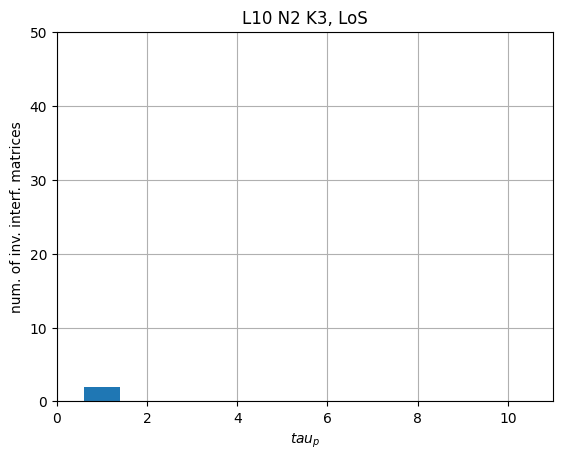

In [55]:
data = pickle.load(open("Results/results_L10N2K3_rician5.pkl", "rb"))
results = data["results"]

plt.bar(results.keys(), results.values())
plt.ylim(0, data["sim_params"["tests"]])
# plt.xlim(0,11)
# plt.yticks(range(0, sim_params["tests"]+1, 1))
# plt.xlabel("$tau_p$")
# plt.ylabel("num. of inv. interf. matrices")
# plt.title("L10 N2 K3, LoS")
plt.grid()
plt.show()
# plt.savefig("plots/L10N2K3_LoS.png")

[[0.27382275 0.00068982]
 [0.00690268 0.07037035]]
inv Z?:  True 

[[0.27382236 0.00069021]
 [0.00690144 0.0703716 ]]
inv Z?:  True 

5


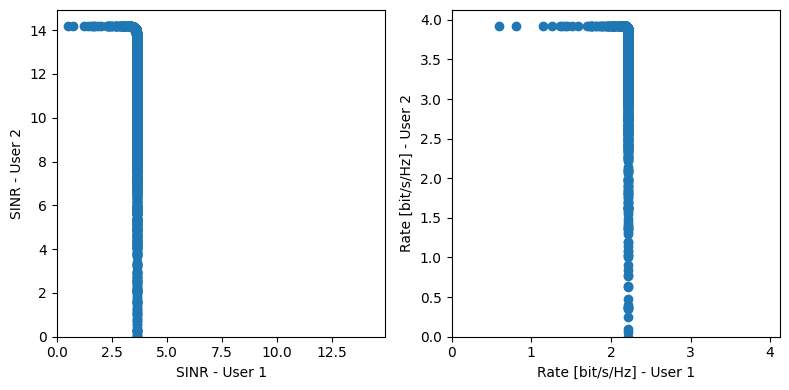

In [6]:
# i = 11
area_block = pickle.load(open("Areas Sim/results_L20N20K2_rician0.pkl", "rb"))

for i in range(5,6):
    inv_interf = True
    (R_block, B_block, HMean_block, kappa_block, UEpos_block, APpos_block) = area_block

    R_spatial_corr_norm = R_block[i,:,:,:,:]
    B_channel_gain =  B_block[i,:,:]
    HMean_norm = HMean_block[i,:,:,:]
    k_rician_factor = kappa_block[i,:,:]
    UEpos = UEpos_block[i,:,:]
    APpos = APpos_block[i,:,:]

    area_values = (R_spatial_corr_norm, B_channel_gain, HMean_norm, k_rician_factor, UEpos, APpos)


    M, u, b, C, sigma, SINR, UEpos, APpos, D_DCC = sim.run_sim(network_params, area_params, sim_params, area_values, i)

    #------------

    p_max = network_params["p_k"]
    K = area_params["K"]

    A = 1/p_max * np.eye(K)
    M_k = np.zeros((K,K,K))
    for k in range(K):
        M_k[k,:,:] = M + u @ A[:,k][:,np.newaxis].T
        print(M_k[k,:,:])
        if funcs.is_invZ(M_k[k,:,:]) == False:
            inv_interf = False
            break
        print("inv Z?: ", funcs.is_invZ(M_k[k,:,:]), "\n")

    #------------

    # for k in range(K):
    #     print("user",k+1)
    #     print(np.linalg.inv(M_k[k,:,:]), "\n")

    #-----------

    # %matplotlib inline
    # if inv_interf == True:
    if True:
        print(i)
        if K==3:
            x,y,z = SINR
        elif K==2:
            x,y = SINR
        rate_x = np.log2(1+np.array(x) )
        rate_y = np.log2(1+np.array(y) )
        if K==3:
            rate_z = np.log2(1+np.array(z) )

        x_max, y_max = np.max(x), np.max(y)
        max_val = max(x_max, y_max)

        if K==3:
            z_max = np.max(z)
            max_val = max(x_max, y_max, z_max)
        
        rate_x_max, rate_y_max = np.max(rate_x), np.max(rate_y)
        max_rate = max(rate_x_max, rate_y_max)

        if K==3:
            rate_z_max = np.max(rate_z)
            max_rate = max(rate_x_max, rate_y_max, rate_z_max)

            # Create a figure with two 3D subplots
            fig, (ax1, ax2) = plt.subplots(1, 2, subplot_kw={'projection': '3d'}, figsize=(8,4))
            # ax = fig.add_subplot(projection='3d')
            ax1.scatter(x,y,z, linewidths=1)
            ax1.set_xlabel("SINR - User 1", fontsize=10)
            ax1.set_ylabel("SINR - User 2", fontsize=10)
            ax1.set_zlabel("SINR - User 3", fontsize=10)
            ax1.set_xlim([0, max_val + 0.05*max_val])
            ax1.set_ylim([0, max_val + 0.05*max_val])
            ax1.set_zlim([0, max_val + 0.05*max_val])
            ax1.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°
            ax2.scatter(rate_x, rate_y, rate_z)
            ax2.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=10)
            ax2.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=10)
            ax2.set_zlabel("Rate [bit/s/Hz] - User 3", fontsize=10)
            ax2.set_xlim([0, max_rate + 0.05*max_rate])
            ax2.set_ylim([0, max_rate + 0.05*max_rate])
            ax2.set_zlim([0, max_rate + 0.05*max_rate])
            ax2.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°

            #(test)
            # ax1.scatter(0.935980, 2.528388, 1.226463, marker='X', linewidths=1)
            # ax2.scatter(0.660822, 1.261142, 0.800651, marker='X', linewidths=20)
        
        elif K==2:
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8,4))
            ax1.scatter(x,y)

            # ax1.plot([0,max_val], [0,max_val])

            ax1.set_xlabel("SINR - User 1", fontsize=10)
            ax1.set_ylabel("SINR - User 2", fontsize=10)
            ax1.set_xlim([0, max_val + 0.05*max_val])
            ax1.set_ylim([0, max_val + 0.05*max_val])

            ax2.scatter(rate_x, rate_y)

            ax2.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=10)
            ax2.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=10)
            ax2.set_xlim([0, max_rate + 0.05*max_rate])
            ax2.set_ylim([0, max_rate + 0.05*max_rate])
        
        plt.tight_layout()
        plt.show()

(0.0, 100.0)

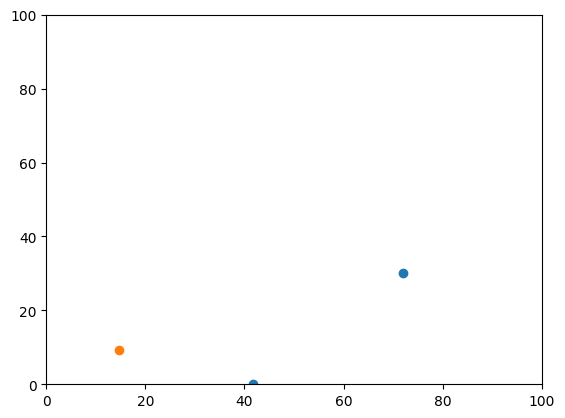

In [107]:
K = area_params["K"]

area = area_params["area"]
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(np.real(UEpos), np.imag(UEpos))
ax.scatter(np.real(APpos), np.imag(APpos))
ax.set_xlim(0, area)
ax.set_ylim(0, area)